### Análise da correlação entre agronegócio, combustiveis fósseis e produção de CO₂

Essa pesquisa tem como objetivo, a criação de um modelo preditivo, pertecente a modalidade de análise supervisionada, que irá investigar a correlação entre a produção de culturas agrícolas, utilização de combustiveis fósseis e a produção de CO₂.

Em meio a data de 10/11/26, essa pesquisa se encontra tendo em seu foco, as seguintes fontes:

- Produção da *cultura agricola milho* em *toneladas* **(t)**.
- Produçaõ da *cultura agricola trigo* em *toneladas* **(t)**.
- Produção da *cultura agricola arroz* em *toneladas* **(t)**.
- Oferta de consumo média em *quilocalorias por pessoa diariamente* **(kcal/pessoa/dia)**.
- Consumo de combustiveis fósseis *(sendo eles: carvão, gás e petróleo)* em *terawatt-hora* **(TWh)**.
- Emissão de *CO₂* na atmosfera *(sendo dividido em: emissão por fontes de combustivel fóssil, e emissão por desmatamento / alteração de solo)* em toneladas **(t)**.

Sendo todas organizadas e agregados no formato '**país/ano**', no período de **1965** á **2023**.

Está pesquisa faz parte da matéria de '*Programação para Ciência de Dados I*', ministrada por '*Ronaldo Rodrigues Martins*', perante o curso '*Ciência de Dados para o Agronegócio*' da FATEC de Catanduva.

### Principal pergunta que essa pesquisa buscar esclarecer:

'A partir dos cinco últimos anos de indicadores agrícolas, alimentares, energéticos e ambientais de um país, é possível prever crescimento superior a 5% na produção das culturas selecionadas, no consumo de combustíveis fósseis e nas emissões de CO₂ no ano seguinte?'

---

### Um sumário rápido para facilitar sua navegação dentre os blocos desse notebook

- [Importar as bibliotecas principais](#importar-as-bibliotecas) (!!! Necessário para a execução do código)
- [Confere se os arquivos originais e seus dados estão presentes](#confere-se-os-dados-originais-estao-presentes)
- [Seleção dos indicadores e definição das variáveis alvo](#selecao-dos-indicadores-e-definicao-das-variaveis-alvo)
- [Não atribuído](#)
- [Não atribuído](#)
- [Não atribuído](#)
- [Não atribuído](#)

<a id="importar-as-bibliotecas"></a>

In [28]:
# Importação das bibliotecas e dependencias

# %pip install pandas numpy matplotlib seaborn scikit-learn

from pathlib import Path
from functools import reduce

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputClassifier

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    hamming_loss,
    ConfusionMatrixDisplay,
)

### Conferência e tratamento da base de dados original

<a id="confere-se-os-dados-originais-estao-presentes"></a>

As seções seguintes tem como objetivo, replicar o processo de tratamento e a conferência de dados efetuado na análise, caso queira utilizar a base já tratada pule para o bloco de [Teste do modelo](#)

Primeiro, efetuamos a conferência dos arquivos originais do Our World in Data.

In [29]:
ROOT = Path.cwd()

print("Pasta do projeto:", ROOT)

if not (ROOT / "Datasets").is_dir():
    raise FileNotFoundError(
        "A pasta de execução não contém Datasets. "
        "Ajuste ROOT para a pasta do projeto."
        "Caso o erro persista, reveja sua instalação, e caso necessário, abra uma issue no GitHub do projeto."
    )

BASE = ROOT / "Datasets" / "Our World in Data"
AGRO = BASE / "Agricultural production"
FOSSIL = BASE / "Fossil fuels"

FONTES = {
    "milho_t": (
        AGRO / "ap-maize-corn_production-tonnes_total.csv"
    ),
    "trigo_t": (
        AGRO / "ap-wheat_production-tonnes_total.csv"
    ),
    "arroz_t": (
        AGRO / "ap-rice_production-tonnes_total.csv"
    ),
    "oferta_kcal_pessoa_dia": (
        AGRO / "ap-all_kcal-capita-day_total.csv"
    ),
    "fosseis_consumo_twh": (
        FOSSIL / "ff-all_energy-consumption-TWh_total.csv"
    ),
    "co2_t": (
        BASE / "ce_co2-production_fossil-and-land.csv"
    ),
}

inventario = pd.DataFrame([
    {
        "variavel": nome,
        "arquivo": caminho.name,
        "existe": caminho.exists(),
        "bytes": (
            caminho.stat().st_size
            if caminho.exists()
            else 0
        ),
    }
    for nome, caminho in FONTES.items()
])


display(inventario)

if inventario["bytes"].eq(0).any():
    raise ValueError(
        "Há arquivos ausentes ou vazios. "
        "Disponibilizem os dados reais antes de continuar."
    )

Pasta do projeto: c:\Users\Faveni\Documents\analise-agro-energia-poluicao


,variavel,arquivo,existe,bytes
0,milho_t,ap-maize-corn_production-tonnes_total.csv,True,349463
1,trigo_t,ap-wheat_production-tonnes_total.csv,True,279996
2,arroz_t,ap-rice_production-tonnes_total.csv,True,289217
3,oferta_kcal_pessoa_dia,ap-all_kcal-capita-day_total.csv,True,393955
4,fosseis_consumo_twh,ff-all_energy-consumption-TWh_total.csv,True,352187
5,co2_t,ce_co2-production_fossil-and-land.csv,True,1628416


Agora que confirmamos a existência dos arquivos, e de um contêudo dentro deles, passamos para a conferência de seus dados.

In [30]:
dados_originais = {}
problemas = []

for nome, caminho in FONTES.items():
    print(f"\n{'=' * 60}")
    print("VARIÁVEL:", nome)
    print("ARQUIVO:", caminho.name)

    if not caminho.is_file():
        problemas.append(f"{nome}: arquivo não encontrado")
        print("ERRO: arquivo não encontrado.")
        continue

    tamanho = caminho.stat().st_size
    print("TAMANHO:", tamanho, "bytes")

    if tamanho == 0:
        problemas.append(f"{nome}: arquivo vazio")
        print("ERRO: arquivo vazio.")
        continue

    try:
        df = pd.read_csv(caminho)
    except (pd.errors.ParserError, pd.errors.EmptyDataError,
            UnicodeDecodeError) as erro:
        problemas.append(f"{nome}: {erro}")
        print("ERRO DE LEITURA:", erro)
        continue

    dados_originais[nome] = df

    print("DIMENSÕES:", df.shape)
    print("COLUNAS:", df.columns.tolist())

    if "Year" in df.columns:
        print(
            "ANOS:",
            df["Year"].min(),
            "até",
            df["Year"].max()
        )

    display(df.head(3))

if problemas:
    print("\nPROBLEMAS ENCONTRADOS:")
    for problema in problemas:
        print("-", problema)


VARIÁVEL: milho_t
ARQUIVO: ap-maize-corn_production-tonnes_total.csv
TAMANHO: 349463 bytes
DIMENSÕES: (12472, 4)
COLUNAS: ['Entity', 'Code', 'Year', 'Maize (corn) - Production (tonnes)']
ANOS: 1961 até 2024


,Entity,Code,Year,Maize (corn) - Production (tonnes)
0,Afghanistan,AFG,1961,700000.0
1,Afghanistan,AFG,1962,700000.0
2,Afghanistan,AFG,1963,713000.0



VARIÁVEL: trigo_t
ARQUIVO: ap-wheat_production-tonnes_total.csv
TAMANHO: 279996 bytes
DIMENSÕES: (9900, 4)
COLUNAS: ['Entity', 'Code', 'Year', 'Wheat - Production (tonnes)']
ANOS: 1961 até 2024


,Entity,Code,Year,Wheat - Production (tonnes)
0,Afghanistan,AFG,1961,2279000.0
1,Afghanistan,AFG,1962,2279000.0
2,Afghanistan,AFG,1963,1947000.0



VARIÁVEL: arroz_t
ARQUIVO: ap-rice_production-tonnes_total.csv
TAMANHO: 289217 bytes
DIMENSÕES: (10229, 4)
COLUNAS: ['Entity', 'Code', 'Year', 'Rice - Production (tonnes)']
ANOS: 1961 até 2024


,Entity,Code,Year,Rice - Production (tonnes)
0,Afghanistan,AFG,1961,319000.0
1,Afghanistan,AFG,1962,319000.0
2,Afghanistan,AFG,1963,319000.0


... (2 outputs left out)


VARIÁVEL: fosseis_consumo_twh
ARQUIVO: ff-all_energy-consumption-TWh_total.csv
TAMANHO: 352187 bytes
DIMENSÕES: (11989, 4)
COLUNAS: ['Entity', 'Code', 'Year', 'Fossil fuels']
ANOS: 1800 até 2025


,Entity,Code,Year,Fossil fuels
0,Afghanistan,AFG,1980,5.626187
1,Afghanistan,AFG,1981,6.568556
2,Afghanistan,AFG,1982,7.182244



VARIÁVEL: co2_t
ARQUIVO: ce_co2-production_fossil-and-land.csv
TAMANHO: 1628416 bytes
DIMENSÕES: (40979, 6)
COLUNAS: ['Entity', 'Code', 'Year', 'Total (fossil fuels and land-use change)', 'Land-use change', 'Fossil fuels']
ANOS: 1850 até 2024


,Entity,Code,Year,Total (fossil fuels and land-use change),Land-use change,Fossil fuels
0,Afghanistan,AFG,1850,NaN,2827069.0,NaN
1,Afghanistan,AFG,1851,NaN,2848760.0,NaN
2,Afghanistan,AFG,1852,NaN,2868252.5,NaN


## Seleção dos indicadores e definição das variáveis-alvo

<a id="selecao-dos-indicadores-e-definicao-das-variaveis-alvo"></a>

A produção agrícola será representada pela soma da produção de milho, trigo e arroz, em toneladas. Esse agregado representa exclusivamente as três culturas selecionadas, e não a produção agrícola total do país.

A variável alimentar representa a disponibilidade de energia alimentar em quilocalorias por pessoa por dia, não a ingestão individual realmente observada.

Para CO₂, será utilizada a série “Total (fossil fuels and land-use change)”, que inclui combustíveis fósseis e mudança do uso da terra, em toneladas.

Os dados serão integrados por código do país e ano.

In [55]:
# Nome simplificado: nome original da coluna.
COLUNAS = {
    "milho_t": "Maize (corn) - Production (tonnes)",
    "trigo_t": "Wheat - Production (tonnes)",
    "arroz_t": "Rice - Production (tonnes)",
    "oferta_kcal_pessoa_dia":
        "All food - Food available for consumption (kilocalories per day per capita)",
    "fosseis_consumo_twh": "Fossil fuels",
    "co2_t": "Total (fossil fuels and land-use change)",
}

# Tabela de nomes para apresentação.
nomes = dados_originais["oferta_kcal_pessoa_dia"][
    ["Code", "Entity"]
].drop_duplicates("Code")

painel = None

for nome, coluna in COLUNAS.items():
    tabela = dados_originais[nome][
        ["Code", "Year", coluna]
    ].copy()

    tabela = tabela.rename(columns={coluna: nome})

    # Triagem: mantém códigos de três letras.
    tabela = tabela[
        tabela["Code"].astype("string").str.fullmatch(
            "[A-Z]{3}", na=False
        )
    ]

    tabela["Year"] = pd.to_numeric(
        tabela["Year"], errors="raise"
    ).astype(int)

    tabela[nome] = pd.to_numeric(
        tabela[nome], errors="raise"
    )

    if painel is None:
        painel = tabela
    else:
        painel = painel.merge(
            tabela,
            on=["Code", "Year"],
            how="outer",
            validate="one_to_one"
        )

painel = painel.merge(nomes, on="Code", how="left")
painel = painel.sort_values(["Code", "Year"])

if painel.duplicated(["Code", "Year"]).any():
    raise ValueError("Existem linhas repetidas por código e ano.")

## Produção das culturas selecionadas

Somamos milho, trigo e arroz somente quando as três produções
estão disponíveis. Esse valor não representa toda a produção
agrícola do país.

Também identificamos a cultura mais produzida, em massa, entre
as três selecionadas.

In [59]:
CULTURAS = ["milho_t", "trigo_t", "arroz_t"]

if (painel[CULTURAS] < 0).any().any():
    raise ValueError("Existem produções negativas: investigar.")

painel["agro_total_t"] = painel[CULTURAS].sum(
    axis=1, min_count=3
)

# Só classifica a cultura quando as três estão presentes e o total é positivo.
completo = painel["agro_total_t"] > 0
valores = painel.loc[completo, CULTURAS]

painel["cultura_principal"] = pd.Series(
    pd.NA, index=painel.index, dtype="string"
)

principal = valores.idxmax(axis=1)

# Se duas ou mais culturas tiverem o mesmo máximo, registra empate.
empate = valores.eq(valores.max(axis=1), axis=0).sum(axis=1) > 1
principal.loc[empate] = "empate"

painel.loc[completo, "cultura_principal"] = principal

In [60]:
INDICADORES = list(COLUNAS) + ["agro_total_t"]

# Exclui linhas sem nenhum indicador.
painel = painel.dropna(subset=INDICADORES, how="all")

resumo = []

for indicador in INDICADORES:
    observados = painel.dropna(subset=[indicador])

    resumo.append({
        "indicador": indicador,
        "valores": len(observados),
        "ausentes": painel[indicador].isna().sum(),
        "codigos_com_dados": observados["Code"].nunique(),
        "primeiro_ano": observados["Year"].min(),
        "ultimo_ano": observados["Year"].max(),
    })

display(pd.DataFrame(resumo))

print("Estatísticas dos indicadores:")
display(painel[INDICADORES].describe().round(2))

,indicador,valores,ausentes,codigos_com_dados,primeiro_ano,ultimo_ano
0,milho_t,9507,13165,175,1961,2024
1,trigo_t,7013,15659,125,1961,2024
2,arroz_t,7422,15250,142,1961,2024
3,oferta_kcal_pessoa_dia,10187,12485,192,1961,2023
4,fosseis_consumo_twh,10612,12060,219,1965,2025
5,co2_t,20936,1736,194,1850,2024
6,agro_total_t,4591,18081,94,1961,2024


Estatísticas dos indicadores:


,milho_t,trigo_t,arroz_t,oferta_kcal_pessoa_dia,fosseis_consumo_twh,co2_t,agro_total_t
count,9.507000e+03,7.013000e+03,7.422000e+03,10187.00,10612.00,2.093600e+04,4.591000e+03
mean,3.982910e+06,4.465514e+06,4.490757e+06,2615.36,511.00,1.311798e+08,1.941908e+07
std,2.369198e+07,1.333175e+07,2.004793e+07,534.55,2241.26,5.129085e+08,6.279228e+07
min,0.000000e+00,0.000000e+00,0.000000e+00,1318.72,0.00,-8.456025e+07,0.000000e+00
25%,1.029605e+04,1.000000e+04,1.500000e+04,2185.63,4.17,5.253225e+06,8.565960e+05
50%,1.714200e+05,2.650000e+05,1.310792e+05,2582.67,35.08,2.096073e+07,2.852892e+06
75%,1.126450e+06,2.230000e+06,1.005404e+06,3033.50,228.88,6.543357e+07,1.218118e+07
max,4.122622e+08,1.401000e+08,2.178679e+08,4793.03,39442.56,1.196962e+10,6.425500e+08


As fontes apresentam coberturas diferentes por ano e entidade. Por isso, a quantidade de exemplos disponíveis para os modelos será menor que o número de linhas do painel.

## Teste isolado do Brasil

In [ ]:
brasil = painel[painel["Code"] == "BRA"]

brasil.plot(
    x="Year",
    y=["milho_t", "trigo_t", "arroz_t"],
    figsize=(10, 4),
    title="Produção de milho, trigo e arroz no Brasil"
)

plt.ylabel("Toneladas")
plt.xlabel("Ano")
plt.tight_layout()
plt.show()

Tabela dos últimos anos
Brasil — últimos dez anos registrados:


,Year,milho_t,trigo_t,arroz_t,oferta_kcal_pessoa_dia,fosseis_consumo_twh,co2_t,agro_total_t,cultura_principal
4662,2016,64188310.0,6834421.0,10622189.0,3280.2700,1935.6086,1.752049e+09,81644920.0,milho_t
4663,2017,97910660.0,4342812.0,12464766.0,3296.8203,1960.4471,1.619461e+09,114718238.0,milho_t
4664,2018,82366530.0,5469236.0,11808412.0,3339.5100,1867.5176,1.638630e+09,99644178.0,milho_t
4665,2019,101126410.0,5590815.0,10368639.0,3350.0800,1872.5090,1.714416e+09,117085864.0,milho_t
4666,2020,103990936.0,6344079.0,11091011.0,3322.7500,1723.0978,1.817239e+09,121426026.0,milho_t
4667,2021,88272110.0,7878413.0,11660605.0,3374.6600,1939.3363,2.048132e+09,107811128.0,milho_t
4668,2022,109741960.0,10343182.0,10773990.0,3419.5100,1873.0913,2.132762e+09,130859132.0,milho_t
4669,2023,131949710.0,7730188.0,10285663.0,3423.4500,1883.4370,2.086059e+09,149965561.0,milho_t
4670,2024,114953304.0,7633178.0,10671490.0,NaN,1907.9907,2.082678e+09,133257972.0,milho_t
4671,2025,NaN,NaN,NaN,NaN,1937.3141,NaN,NaN,<NA>


Produção das três culturas
Agregado, energia, emissões e alimentação


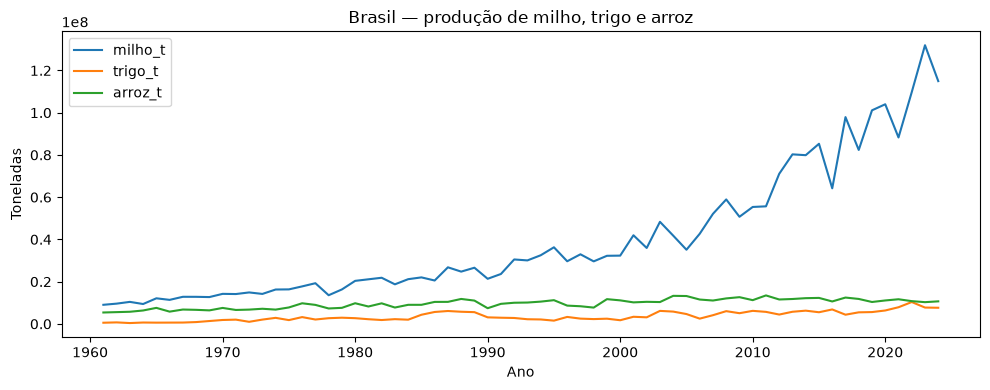

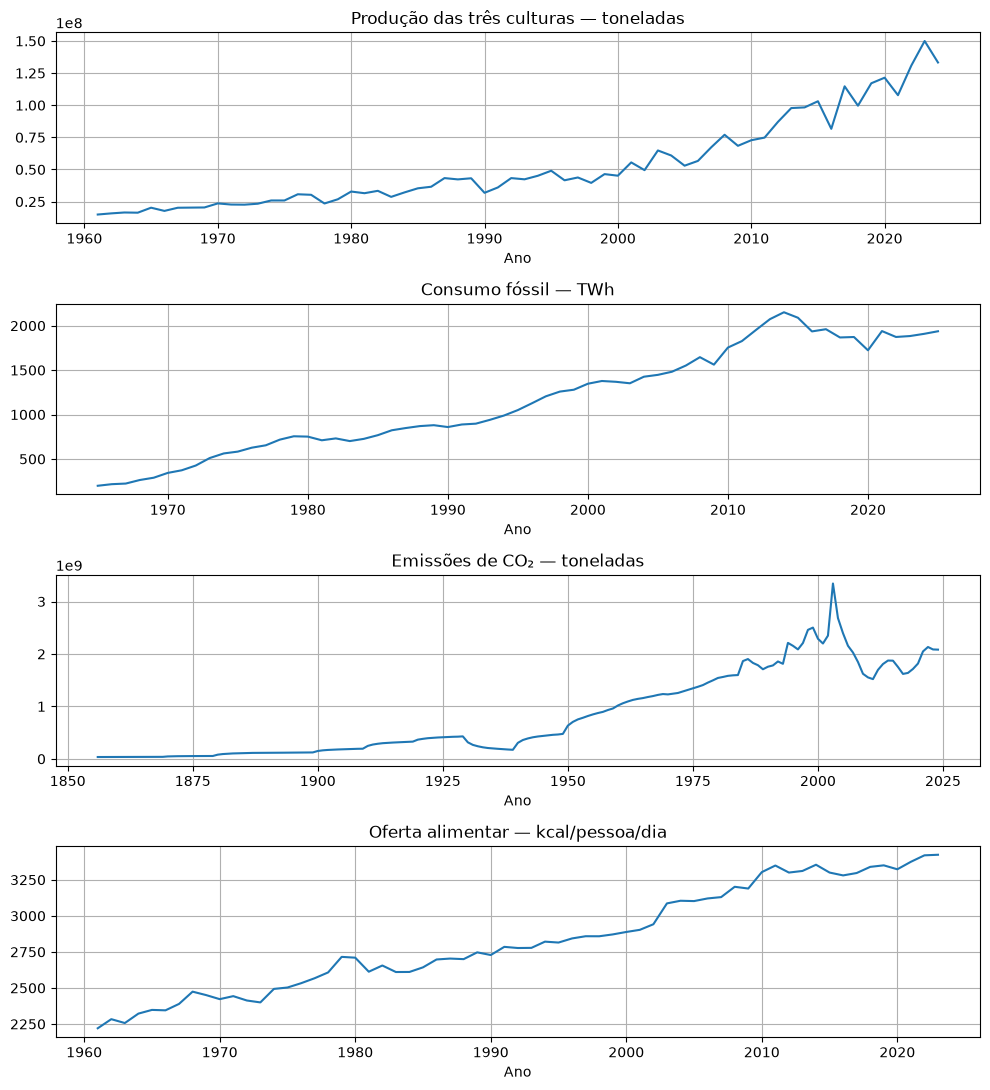

In [62]:
print("Tabela dos últimos anos")

brasil = painel[painel["Code"] == "BRA"].copy()

print("Brasil — últimos dez anos registrados:")
display(
    brasil[
        ["Year"] + INDICADORES + ["cultura_principal"]
    ].tail(10)
)

print("Produção das três culturas")

brasil.plot(
    x="Year",
    y=CULTURAS,
    figsize=(10, 4),
    title="Brasil — produção de milho, trigo e arroz"
)

print("Agregado, energia, emissões e alimentação")

plt.ylabel("Toneladas")
plt.xlabel("Ano")
plt.tight_layout()
plt.show()

graficos = {
    "agro_total_t": "Produção das três culturas — toneladas",
    "fosseis_consumo_twh": "Consumo fóssil — TWh",
    "co2_t": "Emissões de CO₂ — toneladas",
    "oferta_kcal_pessoa_dia": "Oferta alimentar — kcal/pessoa/dia",
}

fig, eixos = plt.subplots(4, 1, figsize=(10, 11))

for eixo, (coluna, titulo) in zip(eixos, graficos.items()):
    eixo.plot(brasil["Year"], brasil[coluna])
    eixo.set_title(titulo)
    eixo.set_xlabel("Ano")
    eixo.grid(True)

plt.tight_layout()
plt.show()

## Salvamento dos dados tratados

Salvamos as tabelas em Datasets/Tratados. A execução sobrescreve
os arquivos gerados, preservando os dados originais.

O painel integrado ainda contém valores ausentes. A seleção dos
históricos completos será feita na preparação dos modelos.

In [61]:
PASTA_TRATADOS = ROOT / "Datasets" / "Tratados"
PASTA_TRATADOS.mkdir(parents=True, exist_ok=True)

agricultura = painel[
    [
        "Code", "Entity", "Year",
        "milho_t", "trigo_t", "arroz_t",
        "agro_total_t", "cultura_principal",
        "oferta_kcal_pessoa_dia",
    ]
].dropna(
    subset=CULTURAS + ["oferta_kcal_pessoa_dia"],
    how="all"
)

combustiveis = painel[
    ["Code", "Entity", "Year", "fosseis_consumo_twh"]
].dropna(subset=["fosseis_consumo_twh"])

co2 = painel[
    ["Code", "Entity", "Year", "co2_t"]
].dropna(subset=["co2_t"])

agricultura.to_csv(PASTA_TRATADOS / "agricultura.csv", index=False)
combustiveis.to_csv(PASTA_TRATADOS / "combustiveis.csv", index=False)
co2.to_csv(PASTA_TRATADOS / "co2.csv", index=False)
painel.to_csv(PASTA_TRATADOS / "painel_pais_ano.csv", index=False)

print("Dados salvos em:", PASTA_TRATADOS)

Dados salvos em: c:\Users\Faveni\Documents\analise-agro-energia-poluicao\Datasets\Tratados


## Primeiros passos para o modelo

In [ ]:
base = pd.read_csv(
    ROOT / "Datasets" / "Pesquisa" / "painel_pais_ano.csv"
)

In [ ]:
INDICADORES_MODELO = [
    "milho_t",
    "trigo_t",
    "arroz_t",
    "oferta_kcal_pessoa_dia",
    "fosseis_consumo_twh",
    "co2_t",
]

modelo_dados = base.copy()
ATRIBUTOS = INDICADORES_MODELO.copy()

for atraso in range(1, 5):
    passado = base[
        ["Code", "Year"] + INDICADORES_MODELO
    ].copy()

    # O dado de 1999 passa a se juntar à referência 2000 quando atraso=1.
    passado["Year"] = passado["Year"] + atraso

    novos_nomes = {}

    for coluna in INDICADORES_MODELO:
        nome = coluna + "_lag" + str(atraso)
        novos_nomes[coluna] = nome
        ATRIBUTOS.append(nome)

    passado = passado.rename(columns=novos_nomes)

    modelo_dados = modelo_dados.merge(
        passado,
        on=["Code", "Year"],
        how="left",
        validate="one_to_one"
    )

In [ ]:
COLUNAS_ALVO = [
    "agro_total_t",
    "fosseis_consumo_twh",
    "co2_t",
]

futuro = base[["Code", "Year"] + COLUNAS_ALVO].copy()

# O valor de 2001 será associado à referência 2000.
futuro["Year"] = futuro["Year"] - 1

futuro = futuro.rename(columns={
    "agro_total_t": "agro_futuro",
    "fosseis_consumo_twh": "fosseis_futuro",
    "co2_t": "co2_futuro",
})

modelo_dados = modelo_dados.merge(
    futuro,
    on=["Code", "Year"],
    how="left",
    validate="one_to_one"
)

In [ ]:
necessarias = ATRIBUTOS + [
    "agro_total_t",
    "agro_futuro",
    "fosseis_futuro",
    "co2_futuro",
]

antes = len(modelo_dados)

modelo_dados = modelo_dados.dropna(
    subset=necessarias
).copy()

# Evita crescimento percentual com base zero ou negativa.
modelo_dados = modelo_dados[
    (modelo_dados["agro_total_t"] > 0)
    & (modelo_dados["fosseis_consumo_twh"] > 0)
    & (modelo_dados["co2_t"] > 0)
].copy()

modelo_dados["y_agro"] = (
    modelo_dados["agro_futuro"]
    / modelo_dados["agro_total_t"] - 1 > 0.05
).astype(int)

modelo_dados["y_fosseis"] = (
    modelo_dados["fosseis_futuro"]
    / modelo_dados["fosseis_consumo_twh"] - 1 > 0.05
).astype(int)

modelo_dados["y_co2"] = (
    modelo_dados["co2_futuro"]
    / modelo_dados["co2_t"] - 1 > 0.05
).astype(int)

ALVOS = ["y_agro", "y_fosseis", "y_co2"]

print("Linhas antes da seleção:", antes)
print("Exemplos completos:", len(modelo_dados))
print("Quantidade de atributos:", len(ATRIBUTOS))

if modelo_dados.empty:
    raise ValueError("Não foram encontradas janelas completas.")

print("Quantidade de exemplos positivos por rótulo:")
display(modelo_dados[ALVOS].sum())

print("Proporção de positivos por rótulo (%):")
display((modelo_dados[ALVOS].mean() * 100).round(2))